# NK–FTPL
정부의 빚은 누가 갚는가?

** 정부가 오늘 지출을 늘리고 세금은 충분히 걷지 않는다면, 그 비용을 **미래 납세자**가 부담할까, 아니면 **오늘 화폐의 구매력**이 부담할까?

이 질문이 시작되는 지점에서 New Keynesian(NK)과 Fiscal Theory of the Price Level(FTPL)이 만나게 된다. 

NK는 금리·총수요·가격 조정의 언어이고, 
FTPL은 국채의 실질가치가 어떤 미래 재정흑자로 뒷받침되는지 묻는 이론이다. 이 둘을 결합하면 **동일한 재정 충격에도 정부와 중앙은행이 어떤 규칙을 따르는지에 따라 물가 반응이 달라질 수 있다**.


우선, 국가가 100원의 국채를 발행했다고 생각해 보자.

국채는 정부가 발행한 부채이면서 민간에게는 자산이다. 민간이 그 국채를 100원의 가치로 받아들이는 이유는 대체로 미래에 정부가 세금을 통해 지급능력을 확보할 것이라고 믿기 때문이다. 그런데 미래 세금·흑자 전망이 무너지고 명목 국채의 약속된 지급액은 그대로라면 어떻게 될까? 정부부채의 *실질가치*가 떨어져야 한다. 그 조정의 한 가지 경로가 물가 상승이다. 

$$
\underbrace{\frac{B^{\mathrm{nom}}_t}{P_t}}_{\text{실질 국채 가치}}
\quad\leftrightarrow\quad
\underbrace{E_t\sum_{j\geq 0}Q_{t,t+j}\,S_{t+j}}_{\text{미래 재정흑자의 현재가치}}
$$

위는 FTPL의 **개념적 정부 가치평가 관계**인데, 정확한 식에는 국채의 만기구조, 할인율, 시점, 정부의 다른 자산·부채가 반영되어야 한다.

- 가계: 오늘 소비와 내일 소비를 비교하며 실질금리 변화에 반응함.
- 기업: 수요가 강하면 가격을 더 올릴 유인이 생김.
- 중앙은행: 인플레이션에 얼마나 강하게 금리로 대응할지 선택함.
- 재정당국: 정부부채가 늘 때 미래 기초재정흑자를 얼마나 늘릴지 선택함.


$x_t$는 산출갭, $\pi_t$는 분기 인플레이션 편차, $i_t$는 분기 명목금리 편차, $b_t$는 정상상태 실질부채로 나누어 정규화한 실질부채 편차이다. 
$s_t$도 동일하게 정규화된 기초재정흑자이고, 충격 $z_t>0$는 흑자를 줄이는 적자 충격이라고 해보자.

경제 전체의 인과 구조는 아래와 같이 5가지로 정리할 수 있다.

$$
\begin{aligned}
\underbrace{x_t}_{\text{현재 수요}}&=E_tx_{t+1}-\frac{1}{\sigma}\underbrace{(i_t-E_t\pi_{t+1})}_{\text{기대 실질금리}} &&\text{(IS: 가계의 기간 간 선택)}\\
\underbrace{\pi_t}_{\text{물가상승}}&=\beta E_t\pi_{t+1}+ \kappa\underbrace{x_t}_{\text{수요 압력}} &&\text{(NKPC: 기업의 가격결정)}\\
i_t&=\phi_\pi\pi_t &&\text{(Taylor rule: 중앙은행)}\\
s_t&=\gamma b_{t-1}-z_t &&\text{(Fiscal rule: 미래의 흑자 조정)}\\
b_t&=\beta^{-1}(b_{t-1}+i_{t-1}-\pi_t)-s_t &&\text{(예산제약: 부채의 회계)}\\
z_{t+1}&=\rho_z z_t &&\text{(충격의 지속성)}.
\end{aligned}
$$


1. **IS:** 명목금리보다 기대인플레이션이 크면 실질금리가 낮아지고, 지금 소비할 유인이 증가함. 단, 이번 모형에는 정부지출의 직접 수요효과가 없음.
2. **NKPC:** 산출갭이 높을수록 기업의 가격인상 압력이 커짐. $\kappa$는 그 민감도임.
3. **Taylor:** $\phi_\pi>1$이면 인플레이션 상승에 명목금리를 더 크게 올리는 적극적 통화정책임. 단, 이것만으로 일반적인 모든 모형의 균형을 판단할 수는 없음.
4. **Fiscal:** $\gamma$가 크면 정부는 부채가 커질 때 기초흑자를 늘려 적극적으로 부채를 상환함. 이 문맥에서 *passive fiscal*이라고 부름.
5. **Budget:** 명목부채의 실질가치는 물가가 상승하면 하락함. 따라서 $\pi_t$가 재정조정의 한 변수로 작동할 수 있음.

충격 시점 $t=0$에 정보가 공개된 뒤에는 다른 불확실성이 없는 perfect-foresight IRF를 구함. 초기 상태는 $b_{-1}=i_{-1}=0$임.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import schur
from pathlib import Path

OUT = Path.cwd()
BETA, SIGMA, KAPPA, RHO = 0.99, 1.0, 0.10, 0.80
SHOCK = 0.001   # unexpected deficit = 0.1% of steady-state real debt (in one quarter)
H = 40
print('numpy', np.__version__, '| horizon', H, '| deficit shock / debt', SHOCK)


numpy 2.5.4 | horizon 40 | deficit shock / debt 0.001


균형을 어떻게 '고를까'?(Blanchard–Kahn)

경제학의 합리적 기대모형은 **회계항등식만 맞는 아무 경로**를 균형이라고 부르지 않는다. 오늘의 소비와 물가는 미래 경로에 대한 기대와 동시에 일관되어야 한다. 따라서 초기 부채가 주어져 있어도 초기 물가와 산출은 점프(jump)할 수 있다.

$$
\underbrace{v_t}_{[x_t,\pi_t,b_{t-1},i_{t-1},z_t]'}
\qquad v_{t+1}=Tv_t.
$$

NKPC를 미래 인플레이션에 대해 풀면
$$
E_t\pi_{t+1}=\frac{\pi_t-\kappa x_t}{\beta}.
$$
이를 IS와 정책준칙에 대입하면 다음 행렬을 얻을 수 있다.

$$
T=\begin{pmatrix}
1+\frac{\kappa}{\sigma\beta}&\frac{\phi_\pi-\beta^{-1}}{\sigma}&0&0&0\\
-\frac{\kappa}{\beta}&\beta^{-1}&0&0&0\\
0&-\beta^{-1}&\beta^{-1}-\gamma&\beta^{-1}&1\\
0&\phi_\pi&0&0&0\\
0&0&0&0&\rho_z
\end{pmatrix}.
$$

이 행렬의 고유값 $\lambda_j$은 각 동학의 증폭·감쇠 정도를 나타냄. $|\lambda_j|<1$은 시간이 지나며 잦아드는 방향, $|\lambda_j|>1$은 폭발하는 방향이다.

$$
\underbrace{\#\{j:|\lambda_j|>1\}}_{\text{폭발적 고유값 개수}}
=\underbrace{2}_{x_t,\pi_t\text{의 점프 자유도}}
\quad\Longrightarrow\quad
\text{이 모형의 유일한 bounded RE 경로 후보}.
$$

이번 선형 시스템에서는 Schur decomposition으로 안정 부분공간을 추출해 초기 $x_0,\pi_0$를 결정한다. 단순히 고유값 개수를 맞추는 것은 원칙적으로 rank condition과 경계 고유값 확인도 동반해야 하는데, 아래 코드에서는 안정 부분공간의 초기조건 사상이 가역적인지도 `np.linalg.solve`로 검사한다.

In [3]:
def transition(phi_pi, gamma, beta=BETA, sigma=SIGMA, kappa=KAPPA, rho=RHO):
    T = np.zeros((5, 5))
    T[0, 0] = 1 + kappa/(sigma*beta)
    T[0, 1] = (phi_pi - 1/beta)/sigma
    T[1, 0] = -kappa/beta
    T[1, 1] = 1/beta
    T[2, 1] = -1/beta
    T[2, 2] = 1/beta-gamma
    T[2, 3] = 1/beta
    T[2, 4] = 1.0
    T[3, 1] = phi_pi
    T[4, 4] = rho
    return T

def solve_irf(phi_pi, gamma, shock=SHOCK, horizon=H):
    T = transition(phi_pi, gamma)
    ordered, Z, nstable = schur(T, output='real', sort='iuc')
    if nstable != 3:
        raise ValueError(f'Non-unique/no bounded RE solution: stable roots={nstable}, expected 3')
    Zstable = Z[:, :nstable]
    initial_predetermined = np.array([0.0, 0.0, shock])  # [b_-1, i_-1, z_0]
    coeff = np.linalg.solve(Zstable[2:, :], initial_predetermined)
    v0 = Zstable @ coeff
    path = np.zeros((horizon+1, 5))
    path[0] = v0
    for t in range(horizon):
        path[t+1] = T @ path[t]
    df = pd.DataFrame(path[:-1], columns=['x', 'pi', 'b_lag', 'i_lag', 'deficit'])
    df['i'] = phi_pi * df['pi']
    df['b'] = (1/BETA-gamma)*df['b_lag'] + df['i_lag']/BETA - df['pi']/BETA + df['deficit']
    df['surplus'] = gamma*df['b_lag']-df['deficit']
    df['price_level'] = df['pi'].cumsum()
    df.index.name = 'quarter'
    return T, df

regimes = {'AM/PF (monetary dominance)': (1.5, 0.30),
           'PM/AF (fiscal dominance)': (0.7, 0.00)}
results = {}
for name, (phi, gamma) in regimes.items():
    T, df = solve_irf(phi, gamma)
    roots = np.linalg.eigvals(T)
    results[name] = (T, df)
    print(f'\n{name}: phi_pi={phi}, gamma={gamma}')
    print('Eigenvalues:', np.round(roots, 5))
    print('Unstable roots:', np.count_nonzero(np.abs(roots)>1+1e-8))
    print('Impact inflation (quarterly pp):', round(100*df.pi.iloc[0], 5))
    print('Impact output gap (%):', round(100*df.x.iloc[0], 5))



AM/PF (monetary dominance): phi_pi=1.5, gamma=0.3
Eigenvalues: [0.7101 +0.j      0.     +0.j      1.05556+0.21776j 1.05556-0.21776j
 0.8    +0.j     ]
Unstable roots: 2
Impact inflation (quarterly pp): 0.0
Impact output gap (%): 0.0

PM/AF (fiscal dominance): phi_pi=0.7, gamma=0.0
Eigenvalues: [1.0101 +0.j 0.     +0.j 1.23828+0.j 0.87283+0.j 0.8    +0.j]
Unstable roots: 2
Impact inflation (quarterly pp): 0.2107
Impact output gap (%): 0.28634


동일한 재정적자인데... 왜 두 세계의 물가는 다를까?

이 실험의 적자 충격은 $z_0=0.001$이고 $\rho_z=0.8$이다. 즉, 첫 분기에 정상상태 실질부채의 0.1%에 해당하는 흑자 감소가 발생하고, 이후 매 분기 충격의 80%가 남음. 이는 GDP 대비 0.1% 적자라는 의미가 아니다.. 

**Monetary Dominance (Active Monetary + Passive Fiscal)**

$\phi_\pi=1.5,\;\gamma=0.30$. 중앙은행은 물가에 강하게 반응하고 재정당국은 부채 증가에 흑자로 대응한다.

$$
z_t\uparrow\rightarrow b_t\uparrow
\rightarrow\underbrace{s_{t+1}\uparrow}_{\text{재정당국의 상환}}
\quad\Longrightarrow\quad
\pi_t=0\quad\text{(이 특정 적자충격에 대해)}.
$$

여기서 물가가 0인 것은 '적자에는 원래 물가효과가 없다'는 보편 법칙이 아니고, 이 다뤄지는 모형엣어의 lump-sum 재정변화가 가계의 수요·기업의 비용 식에 직접 들어가지 않기 때문이다.

**Fiscal Dominance (Passive Monetary + Active Fiscal)**

$\phi_\pi=0.7,\;\gamma=0$. 중앙은행의 물가 대응은 약하고 재정당국은 부채가 늘어도 기초흑자를 체계적으로 늘리지 않는다.

$$
z_t\uparrow\rightarrow
\underbrace{\text{미래 기초흑자 부족}}_{\text{재정적 뒷받침 약화}}
\rightarrow \pi_t\uparrow
\rightarrow \frac{B^{\mathrm{nom}}_t}{P_t}\downarrow.
$$

이 체제에서는 적정한 실질 국채가치를 만들기 위해 현재 물가가 즉시 조정됨. 한편 낮은 실질금리는 산출갭을 높여 NKPC의 인플레이션 경로와 연결된다.

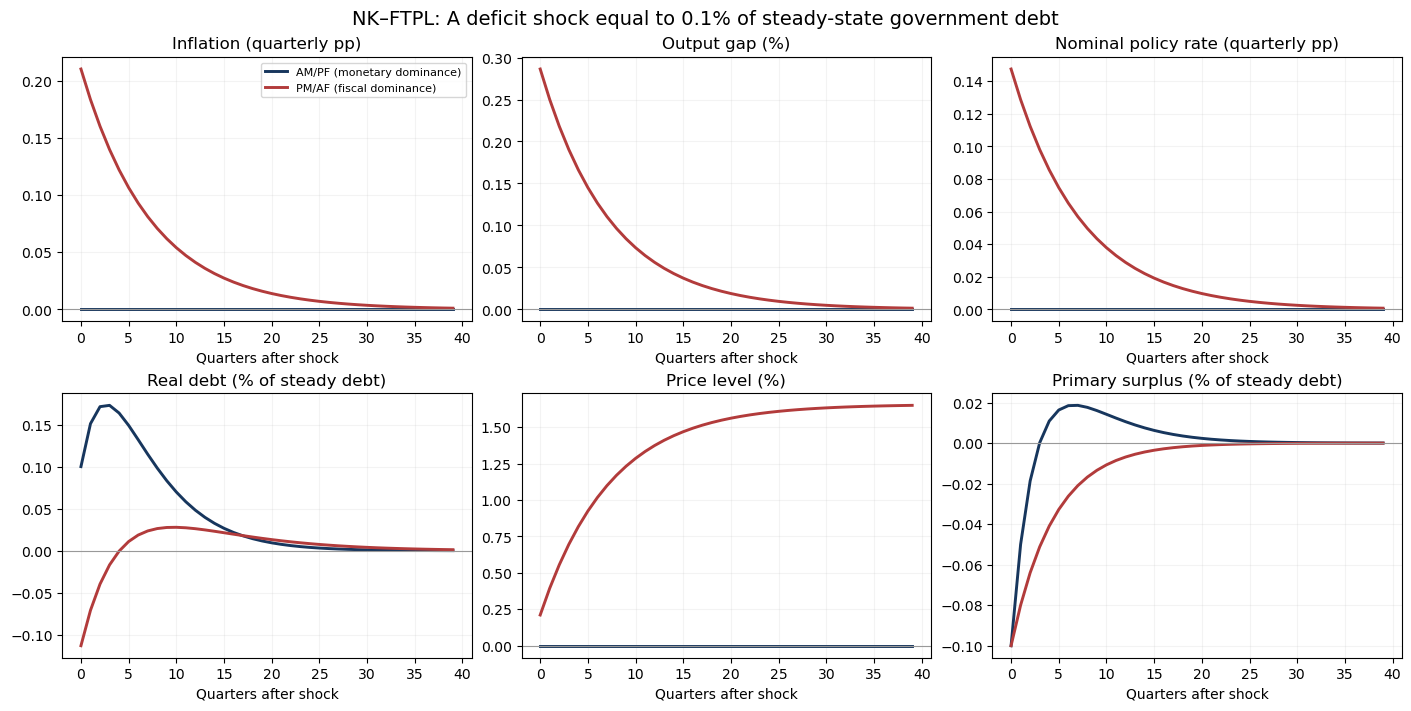

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
fields = [('pi', 'Inflation (quarterly pp)'), ('x', 'Output gap (%)'),
          ('i', 'Nominal policy rate (quarterly pp)'), ('b', 'Real debt (% of steady debt)'),
          ('price_level', 'Price level (%)'), ('surplus', 'Primary surplus (% of steady debt)')]
colors = ['#17365D', '#B23B3B']
for ax, (field, title) in zip(axes.flat, fields):
    for (name, (_, df)), c in zip(results.items(), colors):
        ax.plot(df.index, 100*df[field], lw=2.1, color=c, label=name)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set_title(title)
    ax.set_xlabel('Quarters after shock')
    ax.grid(alpha=0.15)
axes[0,0].legend(fontsize=8)
fig.suptitle('NK–FTPL: A deficit shock equal to 0.1% of steady-state government debt', size=14)
fig.savefig(OUT/'NK_FTPL_IRFs.png', dpi=180, bbox_inches='tight')
plt.show()



- inflation: $100\pi_t$, 분기 인플레이션율의 percentage point 편차.
- output gap: $100x_t$), 정상상태 주변의 근사 퍼센트 편차.
- nominal policy rate: $100i_t$, 분기 명목금리의 percentage point 편차.
- real debt: $100b_t$, 정상상태 실질부채 대비 퍼센트 편차.
- price level: $100\sum_{j=0}^{t}\pi_j$, 로그 물가수준의 근사 퍼센트 편차.

그래프의 충격 직후 실질부채 음(-)의 반응은 '국채 발행액 자체가 줄었다'는 뜻이 아니라, **물가로 할인된 실질 채무가 축소되었다**는 뜻이다.

계산된 $x_t,\pi_t,i_t,b_t,s_t$를 **원래 방정식에 다시 넣었을 때 오차가 0에 가까워야** 한다.

예를 들어 NKPC 잔차는
$$
\varepsilon_t^{\mathrm{NKPC}}
=\pi_t-\beta\pi_{t+1}-\kappa x_t.
$$

IS 잔차는
$$
\varepsilon_t^{\mathrm{IS}}
=x_t-x_{t+1}+\sigma^{-1}(i_t-\pi_{t+1}).
$$

각 시점에서 최대 절댓값 $\max_t|\varepsilon_t|$를 출력한다. 매우 작은 값은 수치해가 **설정한 방정식을 정확하게 풀었다**는 뜻이다. 하지만 모형의 현실성이나 구조적 파라미터의 경험적 타당성까지 증명하지는 않는다.



In [4]:
for name, (T, df) in results.items():
    phi, gamma = regimes[name]
    x, pi, i = [df[k].to_numpy() for k in ['x','pi','i']]
    b, blag, ilag, deficit, surplus = [df[k].to_numpy() for k in ['b','b_lag','i_lag','deficit','surplus']]
    errors = {
        'IS': x[:-1] - x[1:] + (i[:-1]-pi[1:])/SIGMA,
        'NKPC': pi[:-1] - BETA*pi[1:] - KAPPA*x[:-1],
        'Taylor': i - phi*pi,
        'Fiscal rule': surplus - gamma*blag + deficit,
        'Budget': b - (blag+ilag-pi)/BETA + surplus,
        'Debt transition': blag[1:] - b[:-1],
        'Shock transition': deficit[1:] - RHO*deficit[:-1]
    }
    maxerr = max(np.max(np.abs(e)) for e in errors.values())
    print(f'{name}: maximum absolute equation residual = {maxerr:.3e}')
    assert maxerr < 1e-10


AM/PF (monetary dominance): maximum absolute equation residual = 1.084e-19
PM/AF (fiscal dominance): maximum absolute equation residual = 6.505e-19


## Determinacy: '테일러 원칙'만으로 충분할까?

중앙은행이 $\phi_\pi>1$이면 무조건 물가가 안정된다는 이야기를 종종 들음. 그러나 정부의 재정 반응 $\gamma$를 함께 고려하면 더 풍부한 그림이 나옴.

$$
\underbrace{\phi_\pi}_{\text{통화당국의 인플레이션 대응}}
\times
\underbrace{\gamma}_{\text{재정당국의 부채상환 대응}}
\longrightarrow
\underbrace{\text{균형의 존재성과 유일성}}_{\text{determinacy}}.
$$

이 그림은 여러 $(\phi_\pi,\gamma)$ 조합에서 T의 고유값을 반복 계산하여 유일한 국소 유계 균형을 가질 수 있는지 확인한 지도임. 2개의 점프변수에 대응해 2개의 불안정 고유값이 나오는 지역을 구분함. 경계 부근은 고유값이 단위원에 가까워 판정하기 어려우므로 따로 처리함.

주의: 이는 해당 5변수 선형 모형의 고유값 개수에 따른 분류이지, 한국이나 미국이 어떤 체제에 있었다는 실증 판정이 아님.

*English intuition:* Monetary and fiscal policy must be classified as a joint regime; the Taylor principle alone does not characterize the full system.


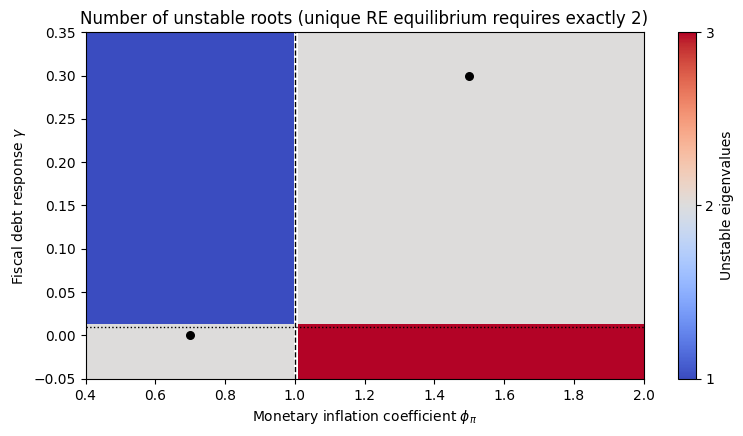

In [5]:
phi_grid = np.linspace(0.4, 2.0, 161)
gamma_grid = np.linspace(-0.05, 0.35, 101)
counts = np.empty((len(gamma_grid), len(phi_grid)), dtype=float)
for j, gam in enumerate(gamma_grid):
    for k, phi in enumerate(phi_grid):
        eig = np.linalg.eigvals(transition(phi, gam))
        if np.min(np.abs(np.abs(eig)-1)) < 1e-5:
            counts[j,k] = np.nan
        else:
            counts[j,k] = np.sum(np.abs(eig) > 1)
fig, ax = plt.subplots(figsize=(9,4.5))
im = ax.imshow(counts, origin='lower', aspect='auto', interpolation='nearest',
    extent=[phi_grid.min(),phi_grid.max(),gamma_grid.min(),gamma_grid.max()],
    vmin=1, vmax=3, cmap='coolwarm')
ax.axvline(1, color='black', lw=1, ls='--')
ax.axhline(1/BETA-1, color='black', lw=1, ls=':')
ax.scatter([1.5, 0.7], [0.3, 0], marker='o', c='black', s=30)
ax.set_xlabel(r'Monetary inflation coefficient $\phi_\pi$')
ax.set_ylabel(r'Fiscal debt response $\gamma$')
ax.set_title('Number of unstable roots (unique RE equilibrium requires exactly 2)')
cbar = fig.colorbar(im, ax=ax, ticks=[1,2,3]); cbar.set_label('Unstable eigenvalues')
fig.savefig(OUT/'NK_FTPL_Determinacy.png',dpi=180,bbox_inches='tight')
plt.show()


In [6]:
summary=[]
for name, (_,df) in results.items():
    d=df.copy(); d.insert(0,'regime',name)
    d.reset_index().to_csv(OUT/('IRF_'+('AM_PF' if name.startswith('AM') else 'PM_AF')+'.csv'), index=False)
    summary.append({'regime':name, 'inflation_impact_quarterly_pp':100*df.pi.iloc[0],
                    'output_impact_pct':100*df.x.iloc[0],
                    'debt_impact_pct_of_debt':100*df.b.iloc[0],
                    'price_level_40q_pct':100*df.price_level.iloc[-1]})
pd.DataFrame(summary).to_csv(OUT/'NK_FTPL_summary.csv',index=False)
display(pd.DataFrame(summary).round(5))
print('Exports saved to', OUT)


,regime,inflation_impact_quarterly_pp,output_impact_pct,debt_impact_pct_of_debt,price_level_40q_pct
0,AM/PF (monetary dominance),0.0000,0.00000,0.10000,0.00000
1,PM/AF (fiscal dominance),0.2107,0.28634,-0.11282,1.64959


Exports saved to /mnt/data/nk_ftpl
